## Dashboard Preparation

Load the final Customer 360 dataset and prepare the main dashboard metrics.


In [1]:
import pandas as pd

customer_360 = pd.read_csv(
    "../data/final/customer_360.csv"
)

customer_360_segmented = pd.read_csv(
    "../data/final/customer_360_segmented.csv"
)

print("Dashboard data loaded successfully")
print("Customer 360:", customer_360.shape)
print("Segmented Customer 360:", customer_360_segmented.shape)

Dashboard data loaded successfully
Customer 360: (5000, 29)
Segmented Customer 360: (5000, 31)


## Dashboard KPI Metrics

Create the key numbers that will appear at the top of the banking dashboard.


In [2]:
total_customers = customer_360["customer_id"].nunique()

total_balance = customer_360["total_balance"].sum()

total_loan_amount = customer_360["total_loan_amount"].sum()

total_transaction_value = customer_360["total_transaction_value"].sum()

loan_customers = (customer_360["loan_count"] > 0).sum()

active_customers = (customer_360["active_account_count"] > 0).sum()

loan_penetration = loan_customers / total_customers * 100

active_customer_rate = active_customers / total_customers * 100

In [3]:
dashboard_kpis = pd.DataFrame({
    "KPI": [
        "Total Customers",
        "Total Customer Balance",
        "Total Loan Amount",
        "Total Transaction Value",
        "Loan Penetration",
        "Active Customer Rate"
    ],
    
    "Value": [
        total_customers,
        total_balance,
        total_loan_amount,
        total_transaction_value,
        loan_penetration,
        active_customer_rate
    ]
})

dashboard_kpis

,KPI,Value
0,Total Customers,5.000000e+03
1,Total Customer Balance,4.296751e+08
2,Total Loan Amount,7.367617e+08
3,Total Transaction Value,2.290646e+07
4,Loan Penetration,3.038000e+01
5,Active Customer Rate,7.288000e+01


## Customer Segment Data

Prepare customer segment distribution for dashboard visualization.


In [4]:
segment_dashboard = (
    customer_360_segmented
    .groupby("segment_name")
    .agg(
        customers=("customer_id", "nunique")
    )
    .reset_index()
)

segment_dashboard["customer_pct"] = (
    segment_dashboard["customers"]
    / total_customers
    * 100
)

segment_dashboard

,segment_name,customers,customer_pct
0,Core Banking Customers,2295,45.90
1,High-Service Customers,1167,23.34
2,High-Value Loan Customers,410,8.20
3,Low Engagement Customers,1128,22.56


## Loan Exposure by Segment

Prepare total loan exposure by customer segment for dashboard visualization.


In [5]:
loan_dashboard = (
    customer_360_segmented
    .groupby("segment_name")
    .agg(
        total_loan_amount=("total_loan_amount", "sum")
    )
    .reset_index()

)

loan_dashboard["loan_pct"] = (
    loan_dashboard["total_loan_amount"]
    / total_loan_amount
    * 100
)

loan_dashboard

,segment_name,total_loan_amount,loan_pct
0,Core Banking Customers,1.563396e+08,21.219839
1,High-Service Customers,9.553669e+07,12.967109
2,High-Value Loan Customers,4.848854e+08,65.813052
3,Low Engagement Customers,0.000000e+00,0.000000


## Transaction Value by Segment

Prepare total transaction value by customer segment for dashboard visualization.


In [6]:
transaction_dashboard = (
    customer_360_segmented
    .groupby("segment_name")
    .agg(
        transaction_value=("total_transaction_value", "sum")
    )
    .reset_index()
)

transaction_dashboard["transaction_pct"] = (
    transaction_dashboard["transaction_value"]
    / total_transaction_value
    * 100
)

transaction_dashboard

,segment_name,transaction_value,transaction_pct
0,Core Banking Customers,13504000.61,58.952796
1,High-Service Customers,6934574.15,30.273439
2,High-Value Loan Customers,2449532.02,10.693628
3,Low Engagement Customers,18356.43,0.080136


## Final Dashboard Dataset

Combine customer count, balance, loan exposure, and transaction value by segment.


In [7]:
dashboard_data = (
    customer_360_segmented
    .groupby("segment_name")
    .agg(
        customers=("customer_id", "nunique"),
        total_balance=("total_balance", "sum"),
        total_loan_amount=("total_loan_amount", "sum"),
        transaction_value=("total_transaction_value", "sum"),
        avg_credit_score=("credit_score", "mean"),
        avg_income=("annual_income", "mean"),
        avg_products=("products_number", "mean")
    )
    .reset_index()
)

dashboard_data

,segment_name,customers,total_balance,total_loan_amount,transaction_value,avg_credit_score,avg_income,avg_products
0,Core Banking Customers,2295,2.517168e+08,1.563396e+08,13504000.61,649.827887,67067.712418,2.290196
1,High-Service Customers,1167,1.269212e+08,9.553669e+07,6934574.15,654.713796,66526.049700,2.331620
2,High-Value Loan Customers,410,5.091761e+07,4.848854e+08,2449532.02,652.463415,63246.585366,3.558537
3,Low Engagement Customers,1128,1.195545e+05,0.000000e+00,18356.43,655.843972,65032.890071,0.500000


In [8]:
dashboard_data["customer_pct"] = (
    dashboard_data["customers"] / total_customers * 100
)

dashboard_data["balance_pct"] = (
    dashboard_data["total_balance"] / total_balance * 100
)

dashboard_data["loan_pct"] = (
    dashboard_data["total_loan_amount"] / total_loan_amount * 100
)

dashboard_data["transaction_pct"] = (
    dashboard_data["transaction_value"] / total_transaction_value * 100
)

dashboard_data

,segment_name,customers,total_balance,total_loan_amount,transaction_value,avg_credit_score,avg_income,avg_products,customer_pct,balance_pct,loan_pct,transaction_pct
0,Core Banking Customers,2295,2.517168e+08,1.563396e+08,13504000.61,649.827887,67067.712418,2.290196,45.90,58.583038,21.219839,58.952796
1,High-Service Customers,1167,1.269212e+08,9.553669e+07,6934574.15,654.713796,66526.049700,2.331620,23.34,29.538881,12.967109,30.273439
2,High-Value Loan Customers,410,5.091761e+07,4.848854e+08,2449532.02,652.463415,63246.585366,3.558537,8.20,11.850256,65.813052,10.693628
3,Low Engagement Customers,1128,1.195545e+05,0.000000e+00,18356.43,655.843972,65032.890071,0.500000,22.56,0.027824,0.000000,0.080136


## Export Dashboard Data

Save the final dashboard dataset so it can be used directly for dashboard development.


In [9]:
dashboard_data.to_csv(
    "../outputs/exports/dashboard_data.csv",
    index=False
)

print("Dashboard data exported successfully")

Dashboard data exported successfully


In [11]:
dashboard_kpis.to_csv(
    "../outputs/exports/dashboard_kpis.csv",
    index=False
)

print("Dashboard KPIs exported successfully")

Dashboard KPIs exported successfully


In [12]:
print("Dashboard preparation data ready")

Dashboard preparation data ready


## Customer Distribution Chart

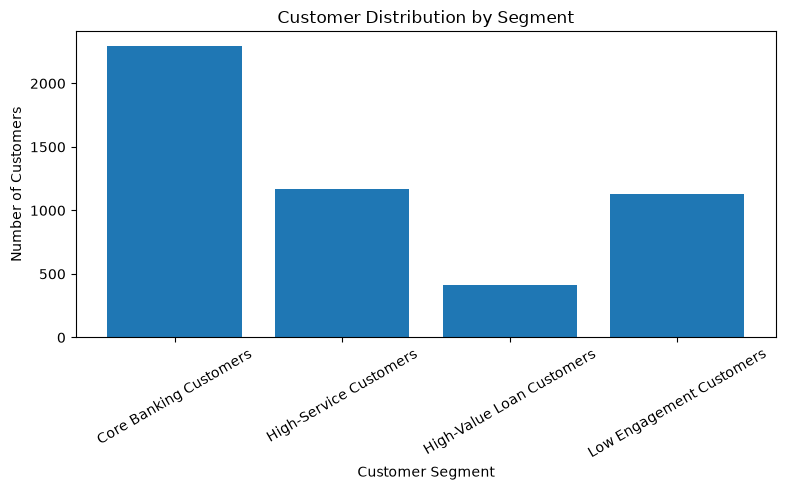

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    segment_dashboard["segment_name"],
    segment_dashboard["customers"]
)

plt.title("Customer Distribution by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.xticks(rotation=30)
plt.tight_layout()

plt.show()

## Loan Exposure by Segment

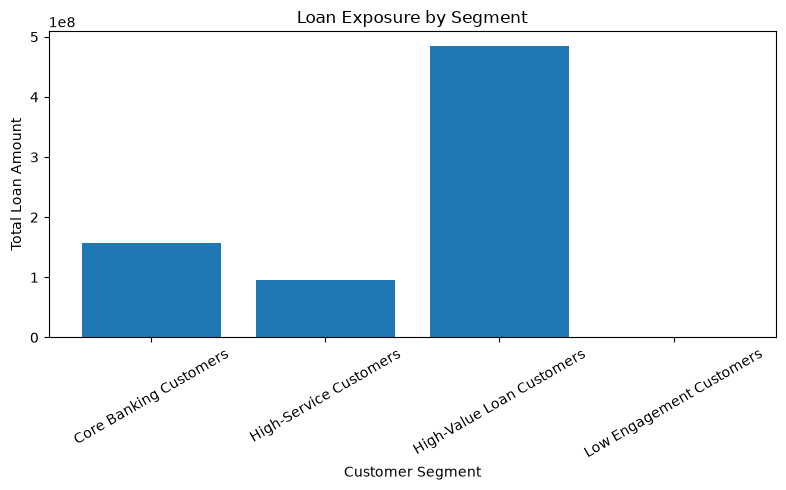

In [14]:
plt.figure(figsize=(8, 5))

plt.bar(
    loan_dashboard["segment_name"],
    loan_dashboard["total_loan_amount"]
)

plt.title("Loan Exposure by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Loan Amount")

plt.xticks(rotation=30)
plt.tight_layout()

plt.show()

## Transaction Value by Segment

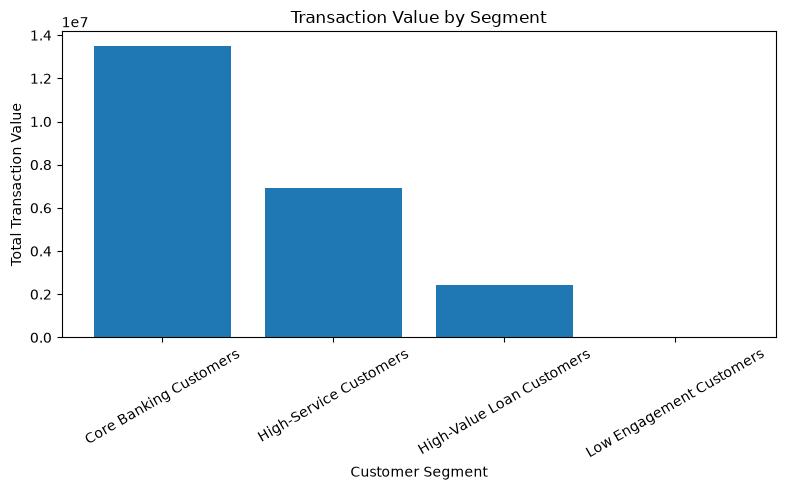

In [15]:
plt.figure(figsize=(8, 5))

plt.bar(
    transaction_dashboard["segment_name"],
    transaction_dashboard["transaction_value"]
)

plt.title("Transaction Value by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Transaction Value")

plt.xticks(rotation=30)
plt.tight_layout()

plt.show()

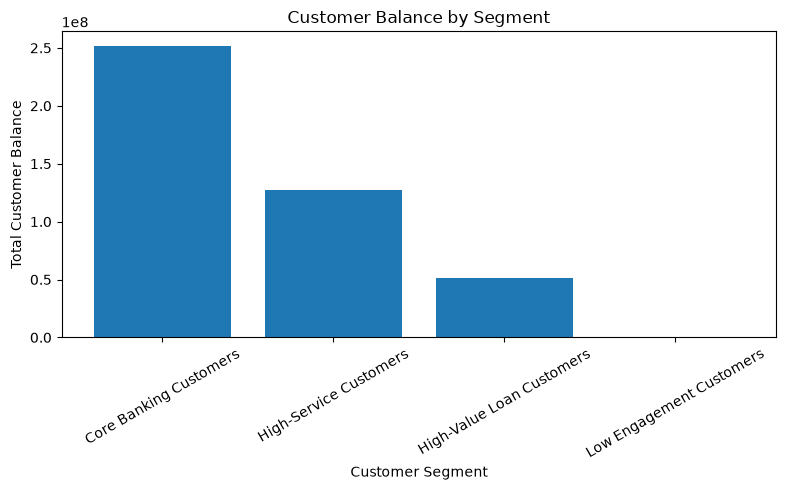

In [16]:
# Customer Balance by Segment
plt.figure(figsize=(8, 5))

plt.bar(
    dashboard_data["segment_name"],
    dashboard_data["total_balance"]
)

plt.title("Customer Balance by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Customer Balance")

plt.xticks(rotation=30)
plt.tight_layout()

plt.show()

In [17]:
# Save Dashboard Charts
plt.figure(figsize=(8, 5))

plt.bar(
    segment_dashboard["segment_name"],
    segment_dashboard["customers"]
)

plt.title("Customer Distribution by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig("../outputs/figures/customer_distribution.png")
plt.close()

print("Customer distribution chart saved")

Customer distribution chart saved


In [18]:
# Loan Exposure Chart
plt.figure(figsize=(8, 5))

plt.bar(
    loan_dashboard["segment_name"],
    loan_dashboard["total_loan_amount"]
)

plt.title("Loan Exposure by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Loan Amount")

plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig("../outputs/figures/loan_exposure.png")
plt.close()

print("Loan exposure chart saved")

Loan exposure chart saved


In [19]:
# Transaction Value
plt.figure(figsize=(8, 5))

plt.bar(
    transaction_dashboard["segment_name"],
    transaction_dashboard["transaction_value"]
)

plt.title("Transaction Value by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Transaction Value")

plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig("../outputs/figures/transaction_value.png")
plt.close()

print("Transaction value chart saved")

Transaction value chart saved


In [20]:
# Customer Balance
plt.figure(figsize=(8, 5))

plt.bar(
    dashboard_data["segment_name"],
    dashboard_data["total_balance"]
)

plt.title("Customer Balance by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Customer Balance")

plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig("../outputs/figures/customer_balance.png")
plt.close()

print("Customer balance chart saved")

Customer balance chart saved


In [21]:
import os

files = [
    "../outputs/exports/dashboard_data.csv",
    "../outputs/exports/dashboard_kpis.csv",
    "../outputs/figures/customer_distribution.png",
    "../outputs/figures/loan_exposure.png",
    "../outputs/figures/transaction_value.png",
    "../outputs/figures/customer_balance.png"
]

for file in files:
    print(file, "->", "Found" if os.path.exists(file) else "Missing")

../outputs/exports/dashboard_data.csv -> Found
../outputs/exports/dashboard_kpis.csv -> Found
../outputs/figures/customer_distribution.png -> Found
../outputs/figures/loan_exposure.png -> Found
../outputs/figures/transaction_value.png -> Found
../outputs/figures/customer_balance.png -> Found


In [1]:
import pandas as pd

dashboard_data = pd.read_csv("../outputs/exports/dashboard_data.csv")
dashboard_kpis = pd.read_csv("../outputs/exports/dashboard_kpis.csv")

print("Dashboard data:")
display(dashboard_data)

print("\nDashboard KPIs:")
display(dashboard_kpis)

Dashboard data:


,segment_name,customers,total_balance,total_loan_amount,transaction_value,avg_credit_score,avg_income,avg_products,customer_pct,balance_pct,loan_pct,transaction_pct
0,Core Banking Customers,2295,2.517168e+08,1.563396e+08,13504000.61,649.827887,67067.712418,2.290196,45.90,58.583038,21.219839,58.952796
1,High-Service Customers,1167,1.269212e+08,9.553669e+07,6934574.15,654.713796,66526.049700,2.331620,23.34,29.538881,12.967109,30.273439
2,High-Value Loan Customers,410,5.091761e+07,4.848854e+08,2449532.02,652.463415,63246.585366,3.558537,8.20,11.850256,65.813052,10.693628
3,Low Engagement Customers,1128,1.195545e+05,0.000000e+00,18356.43,655.843972,65032.890071,0.500000,22.56,0.027824,0.000000,0.080136



Dashboard KPIs:


,KPI,Value
0,Total Customers,5.000000e+03
1,Total Customer Balance,4.296751e+08
2,Total Loan Amount,7.367617e+08
3,Total Transaction Value,2.290646e+07
4,Loan Penetration,3.038000e+01
5,Active Customer Rate,7.288000e+01
